# Part B (Mohamad): interpretability, complexity and the final model
**Kepler KOI exoplanet classification · CMPS 261 project 4.1**

| Step | What happens | Course |
|---|---|---|
| 0 | Load the data, the frozen models and earlier results | |
| 1 | Permutation importance: which inputs does the final model rely on? | Recitation 6, Interpretability lecture |
| 2 | Logistic regression weights: the transparent model's view | Logistic Regression + Regularization lectures |
| 3 | A readable depth-3 decision tree, and what readability costs | Recitation 6 (`plot_tree`) |
| 4 | Complexity table: is the extra complexity worth it? | Project brief, Recitation 6 §11 |
| 5 | Save the final model + model card, and the README results table | Brief: final model downloadable from GitHub |
| 6 | Application: rank the unresolved CANDIDATE KOIs | The scientific use case |

## Step 0: setup

In [1]:
import sys, json, time, io, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn
from sklearn.base import clone
from sklearn.metrics import f1_score
from sklearn.inspection import permutation_importance
from sklearn.tree import DecisionTreeClassifier, plot_tree
warnings.filterwarnings("ignore")

ROOT = Path("..").resolve()
sys.path.append(str(ROOT))
from features import get_X, FEATURES, make_tree_pipeline, RANDOM_STATE

RES, FIG, MODELS = ROOT / "results", ROOT / "results" / "figures", ROOT / "models"
data = pd.read_csv(ROOT / "data" / "processed" / "koi_split.csv", low_memory=False)
train, val, test = (data[data.split == s].reset_index(drop=True) for s in ["train", "val", "test"])
X_train, y_train = get_X(train), train.label.values
X_val, y_val = get_X(val), val.label.values
X_test, y_test = get_X(test), test.label.values

choice = json.load(open(RES / "final_choice.json"))
FINAL, THR = choice["final_model"], choice["thresholds"]
SK = ["LogReg", "DecisionTree", "RandomForest", "AdaBoost"]
M = {n: joblib.load(MODELS / f"{n}.joblib") for n in SK}
dev = pd.read_csv(RES / "B7_development_comparison.csv", index_col=0)
test_res = pd.read_csv(RES / "B7_test_results.csv", index_col=0)
lvl1 = pd.read_csv(RES / "B6_level1_summary.csv", index_col=0)
print(f"final model: {FINAL} (threshold {THR[FINAL]}) | train {len(train)} / val {len(val)} / test {len(test)}")

final model: RandomForest (threshold 0.39) | train 4519 / val 1522 / test 1546


## Step 1: permutation importance (final model, test set)
Shuffle **one** column in the test set and measure how much F1 drops (Recitation 6). A large drop means the model
relies on that column. We compare the final model with logistic regression: do they rely on the same physics?

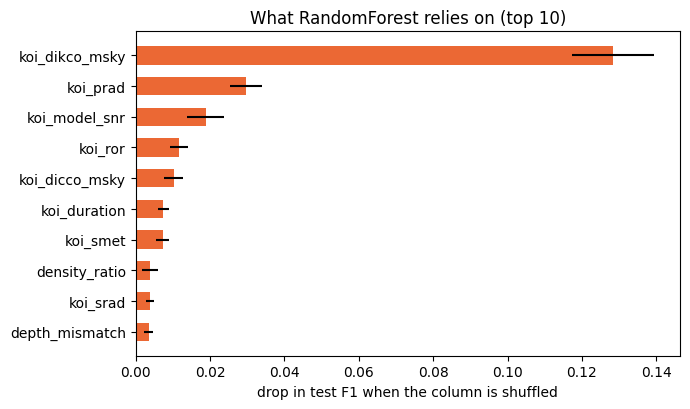

Top 5 per model:


,RandomForest,LogReg
0,koi_dikco_msky,koi_prad
1,koi_prad,koi_period
2,koi_model_snr,koi_dikco_msky
3,koi_ror,koi_depth
4,koi_dicco_msky,koi_insol


In [2]:
def f1_at(threshold):
    return lambda est, X, y: f1_score(y, est.predict_proba(X)[:, 1] >= threshold)

imp = {}
for n in dict.fromkeys([FINAL, "LogReg"]):
    r = permutation_importance(M[n], X_test, y_test, scoring=f1_at(THR[n]), n_repeats=5,
                               random_state=RANDOM_STATE, n_jobs=-1)
    imp[n] = pd.Series(r.importances_mean, index=FEATURES)
    imp[n + " std"] = pd.Series(r.importances_std, index=FEATURES)
imp = pd.DataFrame(imp)
imp.to_csv(RES / "B8_permutation_importance.csv")

top = imp[FINAL].sort_values(ascending=False).head(10)[::-1]
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(top.index, top.values, xerr=imp.loc[top.index, FINAL + " std"], color="#eb6834", height=0.6)
ax.set_xlabel("drop in test F1 when the column is shuffled"); ax.set_title(f"What {FINAL} relies on (top 10)")
plt.tight_layout(); plt.savefig(FIG / "B8_permutation_importance.png", dpi=200); plt.show()
print("Top 5 per model:")
pd.DataFrame({n: imp[n].sort_values(ascending=False).head(5).index.tolist() for n in dict.fromkeys([FINAL, "LogReg"])})

## Step 2: logistic regression weights
Inputs are standardised, so the weights are comparable. **Positive** weight → pushes towards *planet*;
**negative** → towards *false positive*. `missingindicator_x` = the "was missing" column of feature x.

40 non-zero weights of 40


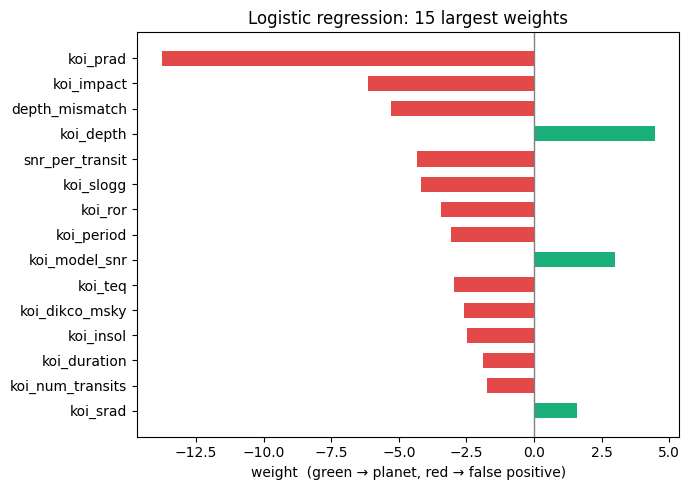

In [3]:
lr = M["LogReg"]
names = lr[:-1].get_feature_names_out(FEATURES) if hasattr(lr[:-1], "get_feature_names_out") else None
w = pd.Series(lr.named_steps["model"].coef_.ravel(), index=names)
print(f"{(w != 0).sum()} non-zero weights of {w.size}")
top = w.reindex(w.abs().sort_values(ascending=False).index).head(15)[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top.values, color=["#1baf7a" if v > 0 else "#e34948" for v in top.values], height=0.6)
ax.axvline(0, color="grey", lw=1); ax.set_xlabel("weight  (green → planet, red → false positive)")
ax.set_title("Logistic regression: 15 largest weights")
plt.tight_layout(); plt.savefig(FIG / "B8_logreg_weights.png", dpi=200); plt.show()
w.sort_values().to_csv(RES / "B8_logreg_weights.csv")

## Step 3: a tree a person can read
A depth-3 tree asks at most 3 yes/no questions. Its validation F1 shows how much accuracy we give up for a model
that can be followed by hand.

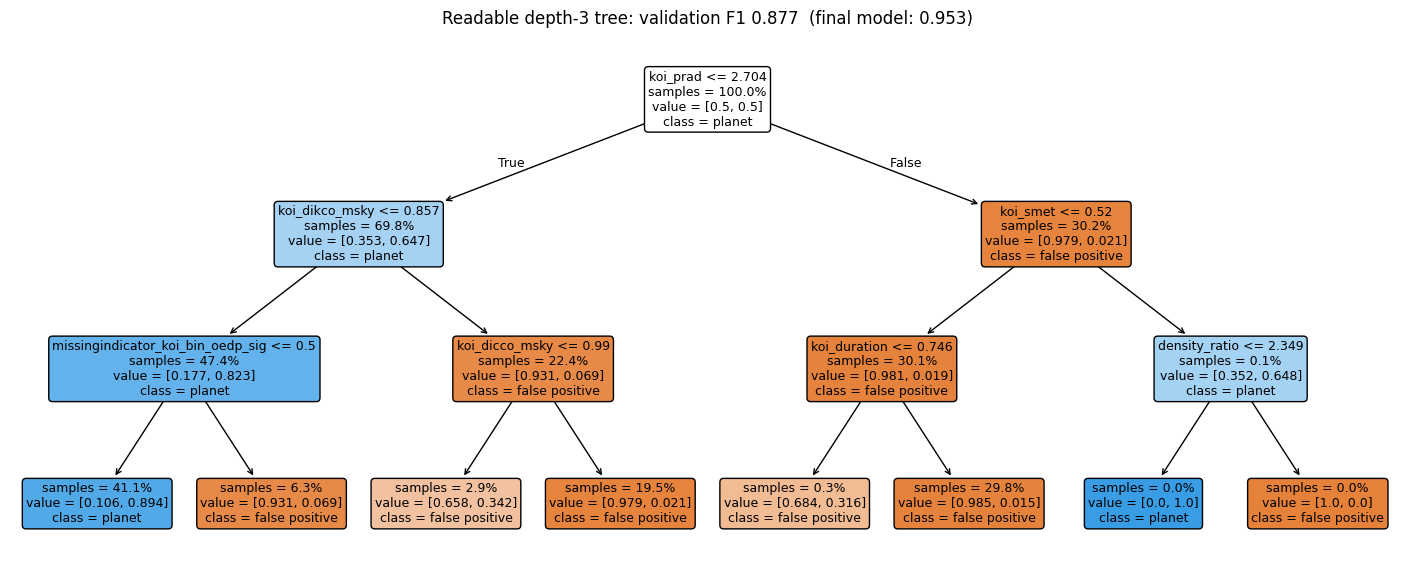

In [4]:
small = make_tree_pipeline(DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=RANDOM_STATE))
small.fit(X_train, y_train)
small_f1 = f1_score(y_val, small.predict(X_val))
names = small[:-1].get_feature_names_out(FEATURES)
plt.figure(figsize=(18, 7))
plot_tree(small.named_steps["model"], feature_names=names, class_names=["false positive", "planet"],
          filled=True, rounded=True, fontsize=9, impurity=False, proportion=True)
plt.title(f"Readable depth-3 tree: validation F1 {small_f1:.3f}  (final model: {dev.loc[FINAL, 'val F1']:.3f})")
plt.savefig(FIG / "B8_readable_tree.png", dpi=200, bbox_inches="tight"); plt.show()

## Step 4: complexity analysis: is the extra complexity worth it?
For each model: search time, time to fit once, prediction time per 1,000 KOIs, size on disk, number of learned
parameters (weights for logistic regression and the network; tree nodes for tree models), validation and test F1.
The neural network's numbers come from Hend's notebook (P4).

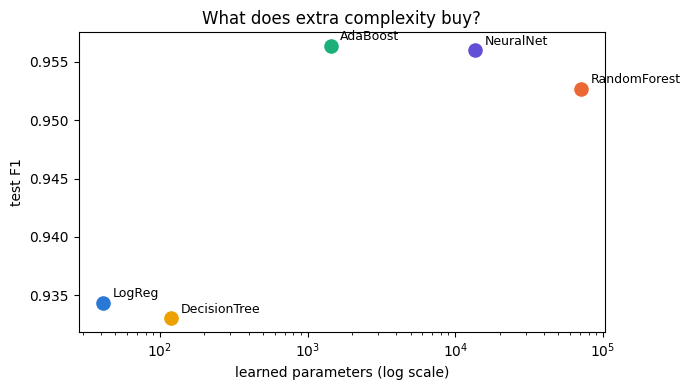

,level,search time (s),fit time (s),predict ms / 1000 KOIs,size (KB),learned parameters,interpretability,val F1,test F1
model,,,,,,,,,
LogReg,Level 1,9.071,0.122,1.562,2.468,41,high (weights),0.934,0.934
DecisionTree,Level 1,2.229,0.155,3.193,5.086,119,high (if shallow),0.916,0.933
RandomForest,Level 1,128.122,2.262,30.100,1303.692,70930,medium-low,0.953,0.953
AdaBoost,Level 1,97.330,2.856,20.845,56.922,1430,medium-low,0.950,0.956
NeuralNet,Level 2,27.400,3.900,NaN,56.056,13569,low,0.953,0.956


In [5]:
def learned(n, est):
    m = est.named_steps["model"]
    if n == "LogReg":
        return m.coef_.size + 1
    if n == "DecisionTree":
        return m.tree_.node_count
    return sum(t.tree_.node_count for t in m.estimators_)

rows = []
for n in SK:
    t0 = time.time(); clone(M[n]).fit(X_train, y_train); fit_s = time.time() - t0
    t0 = time.time()
    for _ in range(5):
        M[n].predict_proba(X_test)
    pred_ms = (time.time() - t0) / 5 / len(X_test) * 1000 * 1000
    rows.append({"model": n, "level": "Level 1", "search time (s)": lvl1.loc[n, "tuning s"], "fit time (s)": fit_s,
                 "predict ms / 1000 KOIs": pred_ms, "size (KB)": (MODELS / f"{n}.joblib").stat().st_size / 1024,
                 "learned parameters": learned(n, M[n]), "interpretability": dev.loc[n, "interpretability"],
                 "val F1": dev.loc[n, "val F1"], "test F1": test_res.loc[n, "F1"]})

nn_set = pd.read_csv(RES / "nn_settings.csv", index_col=0)
nn_cfg = json.load(open(MODELS / "neural_net_config.json"))
chosen = nn_set.loc[nn_cfg["setting"]]
rows.append({"model": "NeuralNet", "level": "Level 2", "search time (s)": nn_set["train_time_s"].sum(),
             "fit time (s)": chosen["train_time_s"], "predict ms / 1000 KOIs": np.nan,
             "size (KB)": (MODELS / "neural_net.pt").stat().st_size / 1024, "learned parameters": int(chosen["params"]),
             "interpretability": dev.loc["NeuralNet", "interpretability"],
             "val F1": dev.loc["NeuralNet", "val F1"], "test F1": test_res.loc["NeuralNet", "F1"]})
cx = pd.DataFrame(rows).set_index("model")
cx.to_csv(RES / "B8_complexity.csv")

colors = {"LogReg": "#2a78d6", "DecisionTree": "#eda100", "RandomForest": "#eb6834", "AdaBoost": "#1baf7a", "NeuralNet": "#6250d6"}
fig, ax = plt.subplots(figsize=(7, 4))
for n, r in cx.iterrows():
    ax.scatter(r["learned parameters"], r["test F1"], s=90, color=colors[n], zorder=3)
    ax.annotate(n, (r["learned parameters"], r["test F1"]), textcoords="offset points", xytext=(7, 4), fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("learned parameters (log scale)"); ax.set_ylabel("test F1")
ax.set_title("What does extra complexity buy?")
plt.tight_layout(); plt.savefig(FIG / "B8_complexity.png", dpi=200); plt.show()
cx.round(3)

In [6]:
best_l1 = choice["best_level1"]
gain = cx.loc["NeuralNet", "test F1"] - cx.loc[best_l1, "test F1"]
lr_gap = cx.loc[FINAL, "test F1"] - cx.loc["LogReg", "test F1"]
print(f"Neural network vs {best_l1}: {gain:+.4f} test F1 "
      f"({int(cx.loc['NeuralNet', 'learned parameters']):,} weights vs {int(cx.loc[best_l1, 'learned parameters']):,} tree nodes; "
      f"fit {cx.loc['NeuralNet', 'fit time (s)']:.1f}s vs {cx.loc[best_l1, 'fit time (s)']:.1f}s; lower interpretability).")
print(f"{FINAL} vs logistic regression: {lr_gap:+.4f} test F1, but {int(cx.loc[FINAL, 'learned parameters']):,} tree nodes "
      f"vs {int(cx.loc['LogReg', 'learned parameters'])} weights.")
print(f"Readable depth-3 tree: validation F1 {small_f1:.3f}.")

Neural network vs RandomForest: +0.0033 test F1 (13,569 weights vs 70,930 tree nodes; fit 3.9s vs 2.3s; lower interpretability).
RandomForest vs logistic regression: +0.0184 test F1, but 70,930 tree nodes vs 41 weights.
Readable depth-3 tree: validation F1 0.877.


**Verdict (write it in your own words after reading the numbers above):** the neural network's gain over the best
Level 1 model is about the size of its own seed-to-seed variation, so the extra complexity is **not** justified.
Among the classical models, the tree ensembles gain about 0.02 F1 over logistic regression; that gain is consistent
across all splits (step 6 of the comparison notebook), so it is real, but logistic regression stays a strong,
fully interpretable alternative.

## Step 5: save the final model, the model card and the README results table
The saved model is exactly the one evaluated on the test set (trained on the training rows).

In [7]:
final_path = MODELS / "final_model.joblib"
joblib.dump(M[FINAL], final_path, compress=3)
tm = test_res.loc[FINAL]
card = {
    "model": FINAL, "threshold": THR[FINAL], "positive_class": "CONFIRMED planet (1) vs FALSE POSITIVE (0)",
    "features": FEATURES, "how_to_use": "X = features.get_X(df); p = model.predict_proba(X)[:, 1]; planet if p >= threshold",
    "selection_rule": choice["rule"], "best_params": lvl1.loc[FINAL, "best params"],
    "validation_F1": float(dev.loc[FINAL, "val F1"]),
    "test_metrics": {k: float(tm[k]) for k in ["F1", "precision", "recall", "accuracy", "FPR"]},
    "data": "NASA Exoplanet Archive KOI cumulative table; 60/20/20 train/val/test split by star (kepid)",
    "n_train": int(len(train)), "n_val": int(len(val)), "n_test": int(len(test)),
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__},
    "created": time.strftime("%Y-%m-%d"),
}
(MODELS / "model_card.json").write_text(json.dumps(card, indent=2))
reloaded = joblib.load(final_path)
assert np.allclose(reloaded.predict_proba(X_test)[:, 1], M[FINAL].predict_proba(X_test)[:, 1])
print(f"saved {final_path.relative_to(ROOT)} ({final_path.stat().st_size / 1e6:.2f} MB) + models/model_card.json, reload OK")

saved models\final_model.joblib (1.46 MB) + models/model_card.json, reload OK


In [8]:
order = ["Baseline", "LogReg", "DecisionTree", "RandomForest", "AdaBoost", "NeuralNet"]
lines = ["| Model | Level | Val F1 | Test F1 | Test precision | Test recall | Fit time (s) |",
         "|---|---|---|---|---|---|---|"]
for n in order:
    level = "baseline" if n == "Baseline" else ("Level 2" if n == "NeuralNet" else "Level 1")
    fit = f"{cx.loc[n, 'fit time (s)']:.1f}" if n in cx.index else "–"
    star = " **(final)**" if n == FINAL else ""
    lines.append(f"| {n}{star} | {level} | {dev.loc[n, 'val F1']:.3f} | {test_res.loc[n, 'F1']:.3f} | "
                 f"{test_res.loc[n, 'precision']:.3f} | {test_res.loc[n, 'recall']:.3f} | {fit} |")
table_md = "\n".join(lines)
(RES / "README_results_table.md").write_text(table_md + "\n")
print(table_md)
print("\nSaved results/README_results_table.md -> paste it into README.md")

| Model | Level | Val F1 | Test F1 | Test precision | Test recall | Fit time (s) |
|---|---|---|---|---|---|---|
| Baseline | baseline | 0.000 | 0.000 | 0.000 | 0.000 | – |
| LogReg | Level 1 | 0.934 | 0.934 | 0.935 | 0.934 | 0.1 |
| DecisionTree | Level 1 | 0.916 | 0.933 | 0.929 | 0.937 | 0.2 |
| RandomForest **(final)** | Level 1 | 0.953 | 0.953 | 0.962 | 0.944 | 2.3 |
| AdaBoost | Level 1 | 0.950 | 0.956 | 0.960 | 0.952 | 2.9 |
| NeuralNet | Level 2 | 0.953 | 0.956 | 0.969 | 0.944 | 3.9 |

Saved results/README_results_table.md -> paste it into README.md


## Step 6: application: rank the unresolved CANDIDATE KOIs
The final model scores the KOIs still labelled CANDIDATE. The top of the list = the most promising targets for
follow-up observation. Sanity check: agreement with the archive's Robovetter score `koi_score`, which the model
never saw.

In [9]:
cand = pd.read_csv(ROOT / "data" / "processed" / "koi_candidates.csv", low_memory=False)
cand["p_planet"] = M[FINAL].predict_proba(get_X(cand))[:, 1]
cand["predicted"] = np.where(cand.p_planet >= THR[FINAL], "planet", "false positive")
cols = [c for c in ["kepoi_name", "p_planet", "predicted", "koi_score", "koi_period", "koi_prad", "koi_model_snr"] if c in cand]
ranking = cand.sort_values("p_planet", ascending=False)[cols]
ranking.to_csv(RES / "B8_candidate_ranking.csv", index=False)
ok = cand.koi_score.notna()
agree = ((cand.p_planet >= THR[FINAL]) == (cand.koi_score >= 0.5))[ok].mean()
print(f"{len(cand)} candidates | predicted planets: {(cand.predicted == 'planet').sum()} | "
      f"agreement with Robovetter (koi_score >= 0.5): {agree:.1%}")
ranking.head(10).round(3)

1976 candidates | predicted planets: 856 | agreement with Robovetter (koi_score >= 0.5): 70.4%


,kepoi_name,p_planet,predicted,koi_score,koi_period,koi_prad,koi_model_snr
335,K00350.01,1.0,planet,0.983,12.991,2.02,42.5
1431,K01053.02,1.0,planet,0.908,46.245,2.46,15.5
1444,K01628.03,1.0,planet,0.000,37.840,1.76,23.7
222,K02531.01,1.0,planet,0.996,17.700,1.96,19.8
201,K02572.01,1.0,planet,1.000,6.377,2.15,17.9
215,K02598.01,1.0,planet,1.000,29.225,1.35,15.7
829,K03337.01,1.0,planet,0.971,11.166,1.56,13.6
42,K01145.01,1.0,planet,0.996,30.587,2.32,33.1
99,K01660.01,1.0,planet,0.985,35.636,1.99,15.7
75,K01357.01,1.0,planet,1.000,3.014,2.87,57.3


### What to write in the report
* **Interpretability:** the top features of the final model (B8_permutation_importance) and the logistic regression
  weights; do they make physical sense? The readable tree and what readability costs.
* **Complexity (Results section):** the complexity table and figure, and the verdict.
* **GitHub:** `models/final_model.joblib` + `models/model_card.json`; paste `results/README_results_table.md` into the README.